In [1]:
# SECTION 1
# Import the libraries for data handling, numeric work, and charts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Confirm the notebook is using the project's virtual environment
print("pandas version :", pd.__version__)
print("numpy version :", np.__version__)

pandas version : 3.0.6
numpy version : 2.5.4


In [2]:
# SECTION 2
# Load the churn data from the project's data folder
df = pd.read_csv("data/Churn_Modeling.csv")

# Confirm the expected size: 10,000 customers
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

# Preview the first five customers
df.head()

Rows : 10000
Columns : 14


,CustomerId,CustomerId.1,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
# SECTION 3
# The file repeats the CustomerId header: the first column holds row numbers,
# and pandas renamed the true customer ID column to CustomerId.1
df = df.rename(columns={"CustomerId": "RowNumber", "CustomerId.1": "CustomerId"})

# Show each column's data type and non-null count
df.info()

# Group columns by type; text columns are categorical, the rest numerical
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
num_cols = df.select_dtypes(include="number").columns.tolist()
print("Categorical :", cat_cols)
print("Numerical :", num_cols)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB
Categorical : ['Surname', 'Geography', 'Gender']
Numerical : ['RowNumber', 'CustomerId', 'CreditScore', 'Age'

In [4]:
# SECTION 4A
# Count missing values in each column
print("Missing values per column :")
print(df.isnull().sum())

# Count fully duplicated rows and repeated customer IDs
print("Duplicate rows :", df.duplicated().sum())
print("Duplicate customer IDs :", df["CustomerId"].duplicated().sum())

# List category labels to catch spelling or case inconsistencies
print("Geography values :", df["Geography"].unique())
print("Gender values :", df["Gender"].unique())

# Zero balances are valid but common enough to shape the Balance distribution
print("Customers with zero balance :", (df["Balance"] == 0).sum())

# Show numeric ranges so impossible values stand out
df.describe()

Missing values per column :
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
Duplicate rows : 0
Duplicate customer IDs : 0
Geography values : <ArrowStringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str
Gender values : <ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
Customers with zero balance : 3617


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


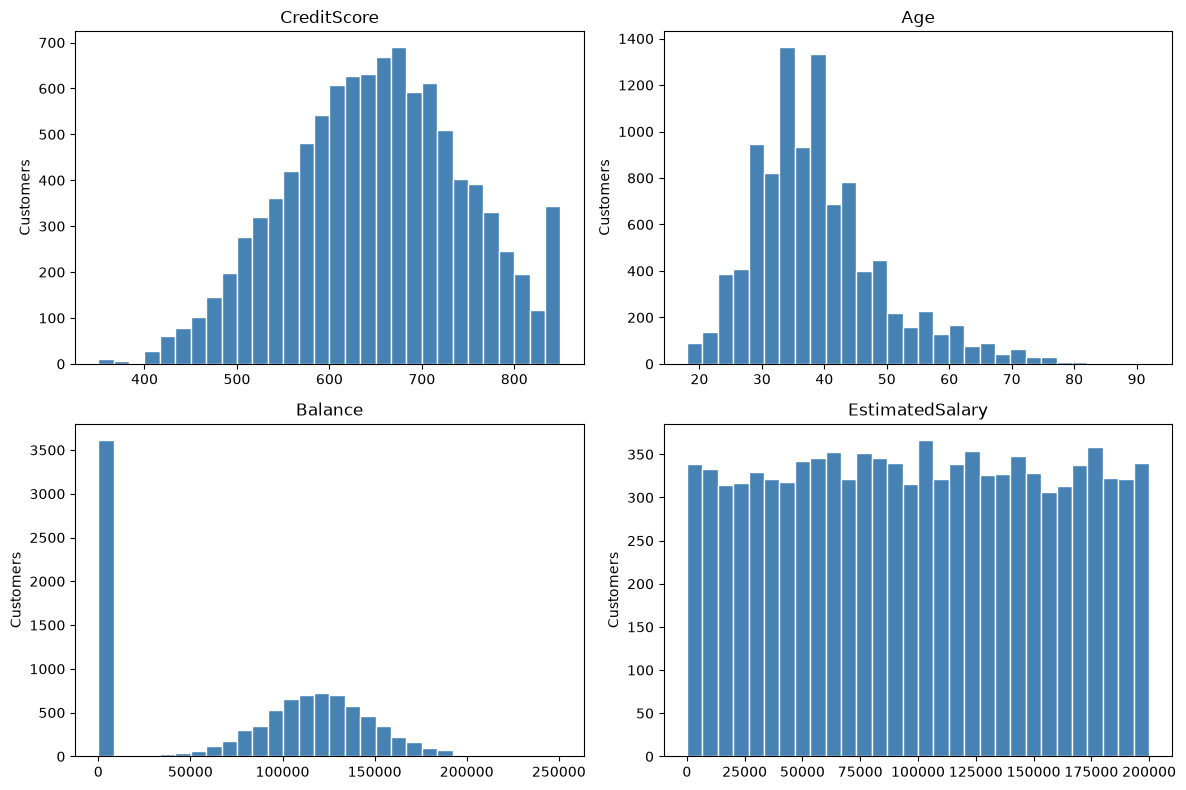

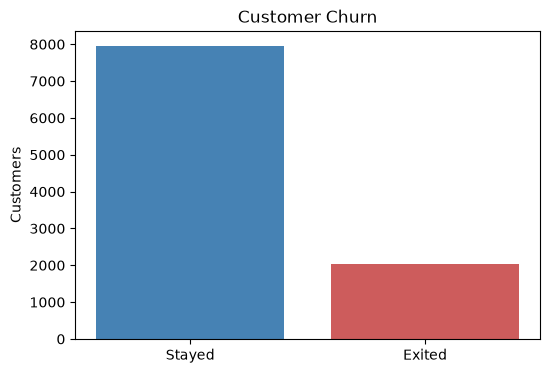

Churn rate : 20.4 %


In [5]:
# SECTION 4B
# Plot the four continuous features in a 2 x 2 grid to compare their shapes
cols = ["CreditScore", "Age", "Balance", "EstimatedSalary"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), cols):
    ax.hist(df[col], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Customers")
plt.tight_layout()
plt.savefig("numeric_distributions.png")
plt.show()

# Compare stayed (0) and exited (1) counts to show the class imbalance
churn_counts = df["Exited"].value_counts()
plt.figure(figsize=(6, 4))
plt.bar(["Stayed", "Exited"], [churn_counts[0], churn_counts[1]], color=["steelblue", "indianred"])
plt.title("Customer Churn")
plt.ylabel("Customers")
plt.savefig("churn_balance.png")
plt.show()

print("Churn rate :", round(df["Exited"].mean() * 100, 1), "%")

Churn by Geography :
           Customers  Churn %
Geography                    
France          5014     16.2
Germany         2509     32.4
Spain           2477     16.7

Churn by Gender :
        Customers  Churn %
Gender                    
Female       4543     25.1
Male         5457     16.5

Churn % by Geography and Gender :
Gender     Female  Male
Geography              
France       20.3  12.7
Germany      37.6  27.8
Spain        21.2  13.1


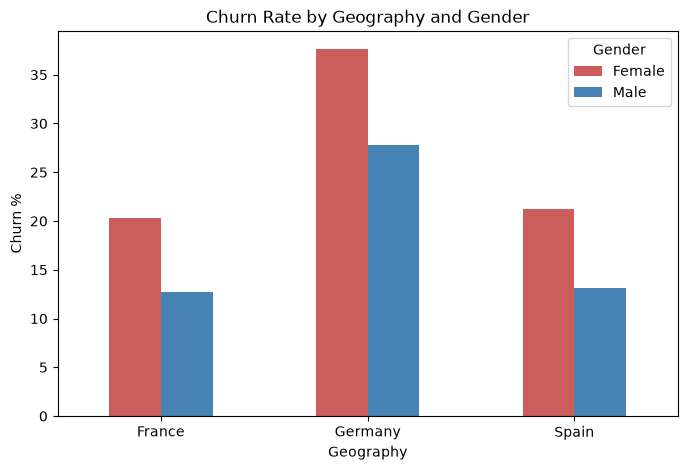

In [6]:
# SECTION 5
# Customer count and churn rate (percent) by geography
geo = df.groupby("Geography")["Exited"].agg(["count", "mean"])
geo["mean"] = (geo["mean"] * 100).round(1)
geo = geo.rename(columns={"count": "Customers", "mean": "Churn %"})
print("Churn by Geography :")
print(geo)
print()

# Same view by gender
gender = df.groupby("Gender")["Exited"].agg(["count", "mean"])
gender["mean"] = (gender["mean"] * 100).round(1)
gender = gender.rename(columns={"count": "Customers", "mean": "Churn %"})
print("Churn by Gender :")
print(gender)
print()

# Pivot table crossing geography and gender to find the highest-risk segments
pivot = df.pivot_table(values="Exited", index="Geography", columns="Gender", aggfunc="mean")
pivot = (pivot * 100).round(1)
print("Churn % by Geography and Gender :")
print(pivot)

# Grouped bar chart of the pivot table
pivot.plot(kind="bar", figsize=(8, 5), color=["indianred", "steelblue"])
plt.title("Churn Rate by Geography and Gender")
plt.ylabel("Churn %")
plt.xticks(rotation=0)
plt.savefig("churn_by_geography_gender.png")
plt.show()

In [7]:
# SECTION 6
# Average of each numeric feature for stayed (0) versus exited (1) customers
num_features = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
print("Average values, stayed (0) vs exited (1) :")
print(df.groupby("Exited")[num_features].mean().round(1))
print()

# Churn rate for each level of the account-behavior features
for col in ["NumOfProducts", "IsActiveMember", "HasCrCard"]:
    table = df.groupby(col)["Exited"].agg(["count", "mean"])
    table["mean"] = (table["mean"] * 100).round(1)
    table = table.rename(columns={"count": "Customers", "mean": "Churn %"})
    print("Churn by", col, ":")
    print(table)
    print()

Average values, stayed (0) vs exited (1) :
        CreditScore   Age  Tenure  Balance  NumOfProducts  EstimatedSalary
Exited                                                                    
0             651.9  37.4     5.0  72745.3            1.5          99738.4
1             645.4  44.8     4.9  91108.5            1.5         101465.7

Churn by NumOfProducts :
               Customers  Churn %
NumOfProducts                    
1                   5084     27.7
2                   4590      7.6
3                    266     82.7
4                     60    100.0

Churn by IsActiveMember :
                Customers  Churn %
IsActiveMember                    
0                    4849     26.9
1                    5151     14.3

Churn by HasCrCard :
           Customers  Churn %
HasCrCard                    
0               2945     20.8
1               7055     20.2



## Section 7: Insights for Model Training and Reporting

**Data quality**

- 10,000 customers, 14 columns, no missing values, no duplicate rows or customer IDs
- The source file repeated the `CustomerId` header; the first column held row numbers and was renamed `RowNumber`
- `Geography` (France, Germany, Spain) and `Gender` (Female, Male) labels are consistent
- 3,617 customers (36 percent) hold a zero `Balance`, a valid value that creates a two-group distribution

**Churn patterns**

- Overall churn is 20.4 percent, so the classes are imbalanced; accuracy alone would overstate performance, which supports selecting the best model by F1-score
- Germany churns at 32.4 percent, about double France (16.2) and Spain (16.7)
- Women churn at 25.1 percent compared with 16.5 percent for men; German women are the highest-risk segment at 37.6 percent
- Churners are older on average (44.8 compared with 37.4 years) and carry higher balances
- Customers with two products churn least (7.6 percent); three or four products churn at 82.7 and 100 percent, though these groups are small
- Inactive members churn at 26.9 percent, nearly double active members at 14.3 percent
- `CreditScore`, `Tenure`, `EstimatedSalary`, and `HasCrCard` show little difference between churners and non-churners

**Preparation decisions for Phase 2**

- Drop `RowNumber`, `CustomerId`, and `Surname`; they identify customers but carry no predictive meaning
- One-hot encode `Geography` and `Gender` with `pd.get_dummies`
- Scale numeric features for Logistic Regression only; tree-based models do not require scaling
- Keep all remaining features; the weak ones are expected to rank low in importance rather than be removed by hand
- Target: `Exited`

In [8]:
# SECTION 8
from sklearn.model_selection import train_test_split

# Separate features from the target, dropping identifier columns
X = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
y = df["Exited"]

# One-hot encode the text columns; drop_first removes one redundant column per feature
X = pd.get_dummies(X, columns=["Geography", "Gender"], drop_first=True, dtype="int")

# Hold out 20 percent of customers for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Confirm sizes, feature columns, and that both sets reflect the churn imbalance
print("Training rows :", X_train.shape[0])
print("Test rows :", X_test.shape[0])
print("Feature columns :", X.shape[1])
print(X.columns.tolist())
print("Training churn rate :", round(y_train.mean() * 100, 1), "%")
print("Test churn rate :", round(y_test.mean() * 100, 1), "%")

Training rows : 8000
Test rows : 2000
Feature columns : 11
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']
Training churn rate : 20.5 %
Test churn rate : 19.7 %


In [9]:
# SECTION 9
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Logistic Regression is scale-sensitive, so it runs inside a pipeline with a scaler
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(random_state=42, max_iter=1000))
    ]),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

# Train each model, predict on the held-out test set, and record the four metrics
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })

# One row per model for side-by-side comparison
results_df = pd.DataFrame(results).set_index("Model").round(3)
print(results_df)

                     Accuracy  Precision  Recall     F1
Model                                                  
Logistic Regression     0.811      0.552   0.201  0.295
Random Forest           0.866      0.758   0.471  0.581
Gradient Boosting       0.868      0.750   0.489  0.592


In [10]:
# SECTION 10
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# SMOTE inside the pipeline resamples training data only; the test set stays untouched
smote_models = {
    "Random Forest + SMOTE": ImbPipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", RandomForestClassifier(n_estimators=100, random_state=42))
    ]),
    "Gradient Boosting + SMOTE": ImbPipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", GradientBoostingClassifier(random_state=42))
    ]),
}

# Train and score each SMOTE model, adding it to the Section 9 results and models
for name, model in smote_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })
    models[name] = model

# All five models, best F1 first
results_df = pd.DataFrame(results).set_index("Model").round(3)
print(results_df.sort_values("F1", ascending=False))

                           Accuracy  Precision  Recall     F1
Model                                                        
Gradient Boosting + SMOTE     0.812      0.517   0.705  0.596
Gradient Boosting             0.868      0.750   0.489  0.592
Random Forest + SMOTE         0.818      0.531   0.649  0.584
Random Forest                 0.866      0.758   0.471  0.581
Logistic Regression           0.811      0.552   0.201  0.295


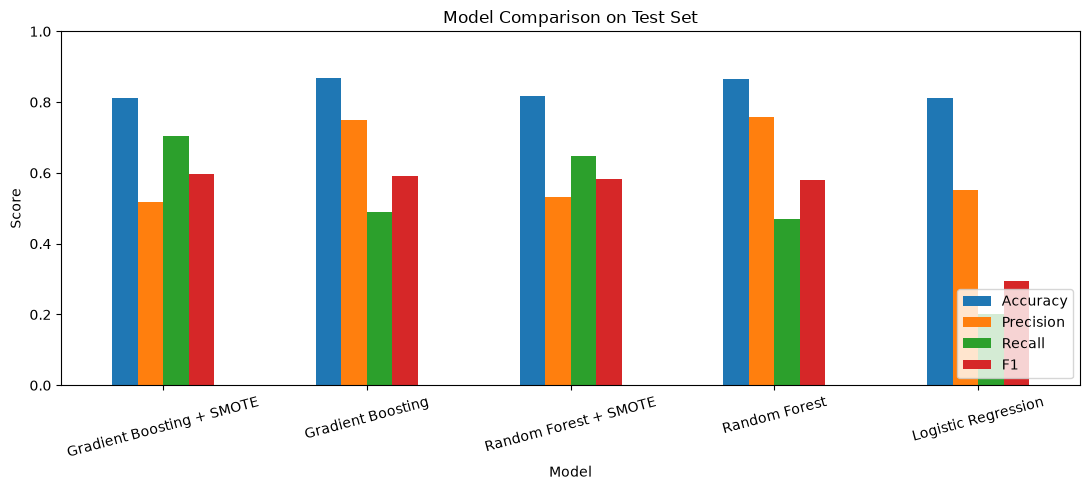

Best model by F1 : Gradient Boosting + SMOTE
F1 : 0.596
Recall : 0.705
Precision : 0.517


In [11]:
# SECTION 11
# Grouped bar chart of all four metrics, models ordered by F1
plot_df = results_df.sort_values("F1", ascending=False)
plot_df.plot(kind="bar", figsize=(11, 5))
plt.title("Model Comparison on Test Set")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()

# Select the model with the highest F1-score, per the assignment
best_name = results_df["F1"].idxmax()
best_model = models[best_name]
print("Best model by F1 :", best_name)
print("F1 :", results_df.loc[best_name, "F1"])
print("Recall :", results_df.loc[best_name, "Recall"])
print("Precision :", results_df.loc[best_name, "Precision"])

In [12]:
# SECTION 12
import os
import joblib

# Save the selected model and the comparison table for deployment and reporting
os.makedirs("models", exist_ok=True)
joblib.dump(best_model, "models/churn_model.pkl")
results_df.to_csv("models/model_comparison.csv")
print("Saved model :", "models/churn_model.pkl")
print("Saved comparison :", "models/model_comparison.csv")

# Reload the saved file and confirm it predicts exactly like the model in memory
loaded_model = joblib.load("models/churn_model.pkl")
match = (loaded_model.predict(X_test) == best_model.predict(X_test)).all()
print("Reloaded predictions match :", match)

Saved model : models/churn_model.pkl
Saved comparison : models/model_comparison.csv
Reloaded predictions match : True


In [13]:
# SECTION 13
import mlflow
import mlflow.sklearn

# Store runs in a local database so the model registry and UI share one source
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("bank-churn")

# Log each model as its own run: settings, test metrics, and the trained model
run_ids = {}
for name, model in models.items():
    with mlflow.start_run(run_name=name):
        y_pred = model.predict(X_test)

        # Pipelines hold the classifier under the "model" step; plain models are the classifier
        if hasattr(model, "named_steps"):
            clf = model.named_steps["model"]
        else:
            clf = model
        mlflow.log_params(clf.get_params())
        mlflow.log_param("smote", "SMOTE" in name)

        mlflow.log_metric("accuracy", accuracy_score(y_test, y_pred))
        mlflow.log_metric("precision", precision_score(y_test, y_pred))
        mlflow.log_metric("recall", recall_score(y_test, y_pred))
        mlflow.log_metric("f1", f1_score(y_test, y_pred))

        # cloudpickle matches the course demo's format; newer MLflow defaults to a stricter one
        mlflow.sklearn.log_model(model, name="model", serialization_format="cloudpickle")
        run_ids[name] = mlflow.active_run().info.run_id

# Confirm one run per model
print(pd.Series(run_ids, name="Run ID"))

2026/10/12 20:39:18 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/12 20:39:18 INFO mlflow.store.db.utils: Updating database tables
2026/10/12 20:39:18 INFO mlflow.tracking.fluent: Experiment with name 'bank-churn' does not exist. Creating a new experiment.
2026/10/12 20:39:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/12 20:39:20 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops

Logistic Regression          9b334c9aed474adba108abfd8597d47f
Random Forest                793296a7c96e4efa8f320beec5c46332
Gradient Boosting            d94d2599346345899ac8794839123280
Random Forest + SMOTE        71d24be0466141288de9deb9f1b27e7b
Gradient Boosting + SMOTE    f1188e1575b54666b8dbb68cc3607ed4
Name: Run ID, dtype: str


In [14]:
# SECTION 15
# Register the best model's logged copy under a permanent registry name
best_run_id = run_ids[best_name]
model_uri = "runs:/" + best_run_id + "/model"
registered = mlflow.register_model(model_uri, "churn-model")

print("Registered model :", registered.name)
print("Version :", registered.version)
print("Source run :", best_name)

Successfully registered model 'churn-model'.
2026/10/12 20:53:07 WARNING mlflow.tracking._model_registry.fluent: Run with id f1188e1575b54666b8dbb68cc3607ed4 has no artifacts at artifact path 'model', registering model based on models:/m-cda0ed77e11b45688e021382fa49da8d instead


Registered model : churn-model
Version : 1
Source run : Gradient Boosting + SMOTE


Created version '1' of model 'churn-model'.
